# Avaliação de Modelos e Interpretação dos Resultados

**Aluna:** Layse Steffany Pereira de Souza · UDF · Sistemas de Informação · Ciência de Dados e Aprendizado de Máquina (2026/2)

**Aula:** 11/11 · Unidade IV – Aprendizado de Máquina
**Atividade:** comparar modelos, analisar métricas e discutir limitações e possíveis erros.
**Entregável:** tabela comparativa dos modelos + conclusão
(ver também `05_tabela_comparativa_modelos.md`).

Responde às perguntas de negócio 2 a 5 e testa as hipóteses H1 a H3 do documento de definição do projeto.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta do notebook.
# No Google Colab, antes de rodar:
#   !git clone https://github.com/LaySteff/ciencia_dados_aprendizado_maquina.git
#   %cd ciencia_dados_aprendizado_maquina/unidade4_aprendizado_maquina
RAIZ = Path.cwd().resolve().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

if config.usando_dados_sinteticos():
    print("AVISO: usando a base SINTÉTICA de demonstração. "
          "Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.")
else:
    print("Usando a amostra real do EMBER.")

AVISO: usando a base SINTÉTICA de demonstração. Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.


In [2]:
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score, precision_score, recall_score,
                             RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix)
from src.preparacao import carregar_tratado

df = carregar_tratado()
X, y = df[config.FEATURES], df[config.ALVO]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

modelos = {
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

## 1. Validação cruzada (5 dobras, conjunto de treino)

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
linhas = []
for nome, m in modelos.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring=["f1", "roc_auc"])
    linhas.append({"modelo": nome,
                   "F1 (CV)": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
                   "AUC (CV)": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"})
tabela_cv = pd.DataFrame(linhas).set_index("modelo")
tabela_cv

,F1 (CV),AUC (CV)
modelo,,
Regressão logística,0.788 ± 0.011,0.877 ± 0.006
Random Forest,0.771 ± 0.003,0.871 ± 0.005
Gradient Boosting,0.769 ± 0.010,0.865 ± 0.003


## 2. Desempenho no conjunto de teste (nunca visto no treino)

In [4]:
probs, linhas = {}, []
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; probs[nome] = p
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    linhas.append({"modelo": nome, "acurácia": accuracy_score(y_te, pred),
                   "precisão": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
                   "F1": f1_score(y_te, pred), "AUC-ROC": roc_auc_score(y_te, p),
                   "taxa FP": fp / (fp + tn), "taxa FN": fn / (fn + tp)})
tabela = pd.DataFrame(linhas).set_index("modelo").round(3)
tabela.join(tabela_cv).to_csv(RAIZ / "unidade4_aprendizado_maquina" / "tabela_comparativa_modelos.csv")
tabela

,acurácia,precisão,recall,F1,AUC-ROC,taxa FP,taxa FN
modelo,,,,,,,
Regressão logística,0.785,0.794,0.725,0.758,0.865,0.162,0.275
Random Forest,0.781,0.802,0.700,0.748,0.856,0.149,0.300
Gradient Boosting,0.783,0.789,0.728,0.757,0.851,0.169,0.272


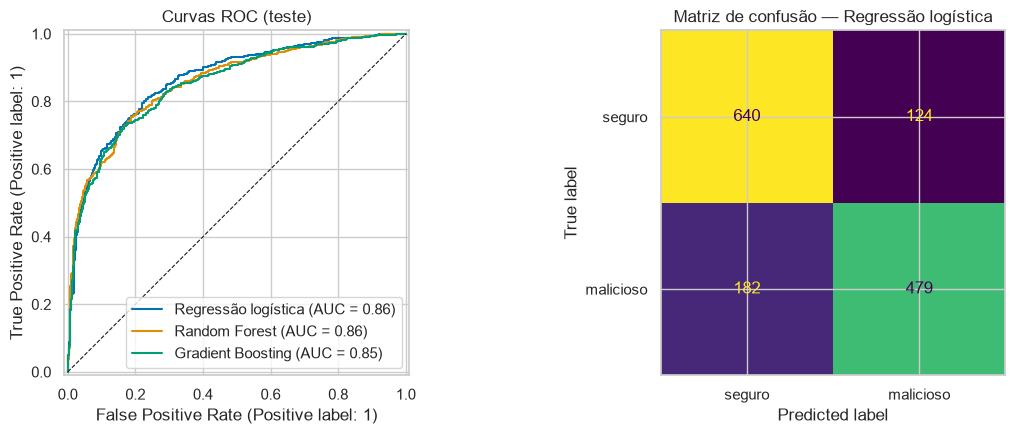

Melhor modelo por AUC-ROC: Regressão logística


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nome, p in probs.items():
    RocCurveDisplay.from_predictions(y_te, p, name=nome, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set_title("Curvas ROC (teste)")
melhor = tabela["AUC-ROC"].idxmax()
ConfusionMatrixDisplay.from_predictions(y_te, (probs[melhor] >= .5).astype(int),
                                        display_labels=["seguro", "malicioso"], ax=axes[1], colorbar=False)
axes[1].set_title(f"Matriz de confusão — {melhor}")
plt.tight_layout(); plt.savefig(FIGURAS / "avaliacao_roc_matriz.png", dpi=120); plt.show()
print("Melhor modelo por AUC-ROC:", melhor)

## 3. Escolha do limiar (pergunta de negócio 3: custo de cada erro)
Meta do projeto: falsos positivos < 5% e falsos negativos < 10%.

In [6]:
p = probs[melhor]
lim = []
for t in np.arange(0.2, 0.81, 0.05):
    tn, fp, fn, tp = confusion_matrix(y_te, (p >= t).astype(int)).ravel()
    lim.append({"limiar": round(t, 2), "taxa FP": fp / (fp + tn), "taxa FN": fn / (fn + tp),
                "atende meta": (fp / (fp + tn) < .05) and (fn / (fn + tp) < .10)})
pd.DataFrame(lim).set_index("limiar").round(3)

,taxa FP,taxa FN,atende meta
limiar,,,
0.20,0.497,0.068,False
0.25,0.412,0.098,False
0.30,0.330,0.123,False
0.35,0.274,0.172,False
0.40,0.226,0.200,False
0.45,0.196,0.238,False
0.50,0.162,0.275,False
0.55,0.140,0.310,False
0.60,0.101,0.343,False


## 4. Importância das variáveis (pergunta de negócio 1)

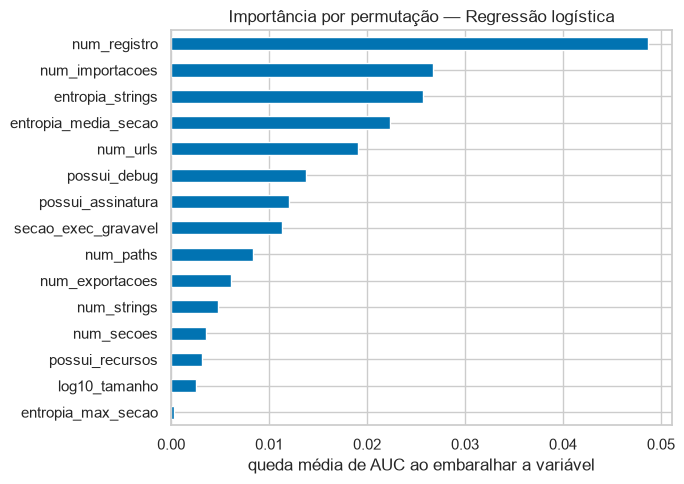

num_registro            0.0487
num_importacoes         0.0267
entropia_strings        0.0257
entropia_media_secao    0.0224
num_urls                0.0190
dtype: float64

In [7]:
imp = permutation_importance(modelos[melhor], X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=42)
importancia = pd.Series(imp.importances_mean, index=config.FEATURES).sort_values()
importancia.plot.barh(figsize=(7, 5), title=f"Importância por permutação — {melhor}")
plt.xlabel("queda média de AUC ao embaralhar a variável"); plt.tight_layout()
plt.savefig(FIGURAS / "importancia_variaveis.png", dpi=120); plt.show()
importancia.sort_values(ascending=False).head(5).round(4)

## 5. Hipótese H1: entropia maior nos maliciosos

In [8]:
seg = df.loc[df.label == 0, "entropia_media_secao"]; mal = df.loc[df.label == 1, "entropia_media_secao"]
stat, pval = mannwhitneyu(mal, seg, alternative="greater")
print(f"Mediana seguros: {seg.median():.2f} | mediana maliciosos: {mal.median():.2f} | p-valor: {pval:.2e}")

Mediana seguros: 5.34 | mediana maliciosos: 6.11 | p-valor: 3.78e-154


## 6. Hipótese H3: desempenho com arquivos mais recentes (deriva temporal)
Treina com jan–ago e testa com set–dez, comparando com a divisão aleatória.

In [9]:
antigo = df["mes_aparicao"] <= "2018-08"
Xa, ya, Xn, yn = X[antigo], y[antigo], X[~antigo], y[~antigo]
linhas = []
for nome, m in modelos.items():
    m.fit(Xa, ya); p_n = m.predict_proba(Xn)[:, 1]
    linhas.append({"modelo": nome, "AUC divisão aleatória": tabela.loc[nome, "AUC-ROC"],
                   "AUC treino antigo → teste recente": roc_auc_score(yn, p_n),
                   "F1 treino antigo → teste recente": f1_score(yn, (p_n >= .5).astype(int))})
temporal = pd.DataFrame(linhas).set_index("modelo").round(3)
temporal["queda de AUC"] = (temporal.iloc[:, 0] - temporal.iloc[:, 1]).round(3)
temporal

,AUC divisão aleatória,AUC treino antigo → teste recente,F1 treino antigo → teste recente,queda de AUC
modelo,,,,
Regressão logística,0.865,0.835,0.706,0.030
Random Forest,0.856,0.831,0.675,0.025
Gradient Boosting,0.851,0.826,0.695,0.025


## 7. Análise de erros (pergunta de negócio 5)

In [10]:
m = modelos[melhor].fit(X_tr, y_tr)
teste = X_te.copy(); teste["real"] = y_te; teste["pred"] = m.predict(X_te)
teste["tipo"] = np.select([(teste.real == 0) & (teste.pred == 1), (teste.real == 1) & (teste.pred == 0)],
                          ["falso positivo", "falso negativo"], "acerto")
cols = ["entropia_media_secao", "num_importacoes", "possui_assinatura", "secao_exec_gravavel", "num_urls"]
teste.groupby("tipo")[cols].mean().round(2).assign(qtd=teste["tipo"].value_counts())

,entropia_media_secao,num_importacoes,possui_assinatura,secao_exec_gravavel,num_urls,qtd
tipo,,,,,,
acerto,5.68,92.19,0.41,0.18,1.90,1119
falso negativo,5.26,111.54,0.50,0.04,1.74,182
falso positivo,5.62,81.28,0.37,0.15,2.29,124


## 8. Conclusão

> ⚠️ Valores obtidos com a base **sintética** de demonstração. Refaça a interpretação após rodar com a amostra real do EMBER.

**Tabela comparativa (teste, limiar 0,5):** ver a célula da seção 2 e `tabela_comparativa_modelos.csv`.

1. **Os três modelos têm desempenho praticamente igual** (AUC entre 0,85 e 0,87, e as diferenças cabem no desvio da validação cruzada). A **regressão logística** ficou um pouco à frente e, por ser mais simples e interpretável, é a escolhida. → **H2 refutada** nestes dados: os modelos de árvore não superaram a regressão logística.
2. **As metas do projeto não foram atingidas** (F1 ≥ 0,90 e AUC ≥ 0,95). Nenhum limiar consegue ao mesmo tempo FP < 5% e FN < 10%. **Escolhendo o limiar:** com 0,25 chegamos a FN ≈ 10%, mas bloqueamos ~41% dos arquivos seguros. Na prática, isso sugere usar o modelo para **priorizar a análise humana**, e não para bloquear arquivos automaticamente.
3. **H1 confirmada:** os maliciosos têm entropia maior (mediana 6,11 contra 5,34; Mann-Whitney p < 0,001).
4. **H3 confirmada:** treinar com jan–ago e testar com set–dez reduz a AUC em ~0,03 e o F1 em ~0,05. O modelo **envelhece** e precisa ser retreinado.
5. **Erros:** os falsos negativos têm entropia normal, muitas importações e frequentemente assinatura. São os malwares "comuns", que as características estáticas não distinguem. Para eles seriam necessárias outras fontes de informação (análise dinâmica, reputação do remetente), que estão fora do escopo.

**Limitações:** base sintética, só características estáticas, imputação feita antes da divisão treino/teste (pequeno vazamento de informação) e ruído de rótulo de ~3%.